In [1]:
import torch, torchvision
from torchvision import transforms
from datasets import load_dataset

C:\Users\litwi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# IMDB Sentiment Classification: RNN vs LSTM

**Goal:** predict whether a movie review is positive or negative.
**Data:** Hugging Face `imdb` (`train` 25k, `test` 25k; ignore the `unsupervised` split, it has no real labels).
**Compare:** TF-IDF + Logistic Regression (baseline) vs RNN vs LSTM.

**Pipeline:** text -> tokens -> indices -> padding / truncation (`max_len`) -> `Embedding` -> RNN/LSTM -> `Linear`

---

## Functions to write (the full list, nothing else)

| # | Function | Purpose |
|---|---|---|
| 1 | `load_imdb()` | download IMDB from Hugging Face, return the `DatasetDict` |
| 2 | `split_train_val` | reuse from the CIFAR project |
| 3 | `tokenize(text)` | lowercase, remove `<br />`, remove punctuation, split into words |
| 4 | `build_vocab(texts, max_size=10000)` | word to index, `<pad>` = 0, `<unk>` = 1 (**train only**) |
| 5 | `encode(text, vocab, max_len)` | list of indices, truncated or padded to `max_len` |
| 6 | `make_loader(texts, labels, vocab, max_len, batch_size, shuffle)` | DataLoader |
| 7 | `run_tfidf_baseline(train_texts, train_labels, val_texts, val_labels)` | returns val accuracy |
| 8 | `build_lstm(vocab_size, emb_dim, hidden_dim)` | `Embedding -> LSTM -> last hidden -> Linear(2)` (uses a small `nn.Module` class inside) |
| 9 | `fit`, `evaluate`, `count_parameters`, `plot_history` | reuse from CIFAR, adapt to text batches, add `clip_grad_norm_` |
| 10 | `run_experiment(name, model_type, hidden_dim, max_len, lr, epochs)` | one row of the results table |
| 11 | `test_final(model, test_loader, device)` | run once on the test set |

---

## Step 1. Data
- [ ] `load_imdb()` and `split_train_val`
- [ ] look at: `print(ds)`, one review text, labels of the first 10 examples (data is sorted by label, so shuffle before splitting), review length distribution (decides `max_len`)

## Step 2. Text to numbers
- [ ] `tokenize`, `build_vocab`, `encode`
- [ ] check: tokenize the first review and print the first 20 tokens

## Step 3. DataLoader
- [ ] `make_loader`
- [ ] check one batch: shape `(batch_size, max_len)`

## Step 4. Baseline without a neural network
- [ ] `run_tfidf_baseline`

## Step 5. Model
- [ ] write the tensor shape after every layer *before* coding:
  `(batch, max_len)` -> Embedding -> `(batch, max_len, emb_dim)` -> LSTM -> `(batch, hidden)` -> Linear -> `(batch, 2)`
- [ ] think: how to pick the "last" hidden state when reviews are padded?
- [ ] `build_lstm`

## Step 6. Training

**Goal:** train the networks on the 20k training reviews and monitor them on the 5k validation reviews.

We reuse the training code from the CIFAR project, adapted to text batches (a batch is a pair `(xb, yb)` of word indices and labels instead of images).

| Function | What it does |
|---|---|
| `fit(model, train_loader, val_loader, epochs, lr, device)` | training loop: forward pass, loss, backward pass, optimizer step; returns a history dict |
| `evaluate(model, loader, loss_fn, device)` | average loss and accuracy on a DataLoader (no gradients) |
| `count_parameters(model)` | number of trainable parameters |
| `plot_history(history)` | train vs validation loss and accuracy curves |

**Details:**
- loss: `CrossEntropyLoss` (the model outputs 2 raw scores, softmax is inside the loss)
- optimizer: Adam
- **gradient clipping** (`clip_grad_norm_`) keeps gradients from exploding, which matters for recurrent networks

**Checks:**
- [x] one batch gives output shape `(64, 2)`
- [x] parameter count matches the hand calculation (Flatten net 262,498; LSTM 166,466)
- [x] curves plotted for both models

---

## Step 7. Experiments

**Goal:** compare models and settings fairly, using **validation accuracy at the best epoch** (not the last epoch, because longer training eventually overfits).

`run_experiment(name, model_type, hidden_dim, max_len, lr, epochs)` builds a model, trains it, and returns one row of the results table.

### Experiments

| # | Experiment | Question |
|---|---|---|
| 1 | Flatten vs LSTM | does reading word order help? |
| 2 | `nn.RNN` vs `nn.LSTM` | do LSTM gates help on long reviews? |
| 3 | `max_len` 100 vs 400 | how much of the review does the model need? |
| 4 | `hidden_dim` 32 vs 128 | does a bigger memory help or just overfit? |
| 5 | (optional) `bidirectional=True` | does reading in both directions help? |
| 6 | (optional) pretrained GloVe in `Embedding` | does transfer learning help on words? |

### Results table (best validation accuracy)

| Model | Params | Best val acc | Best epoch | Notes |
|---|---|---|---|---|
| TF-IDF + LogReg | - | | | baseline, no neural network |
| Embedding + Flatten | 262,498 | 0.726 | 10 | overfits from epoch 1 |
| LSTM (hidden 32, max_len 200) | 166,466 | 0.828 | 3 | mild overfitting |
| RNN (hidden 32, max_len 200) | | | | |
| LSTM, `max_len` 100 | | | | |
| LSTM, `max_len` 400 | | | | |
| LSTM, `hidden_dim` 128 | | | | |

### Questions to answer in notes
1. Which model is best on validation, and by how much over the TF-IDF baseline?
2. Why does LSTM beat Flatten with fewer parameters?
3. Does plain RNN lose to LSTM? If yes, where (slow start, unstable curves, long reviews)?
4. What happens to accuracy and training time when `max_len` grows?

| Experiment | What it tests |
|---|---|
| `nn.RNN` vs `nn.LSTM` | does LSTM handle long reviews better? |
| `max_len` 100 vs 400 | effect of sequence length |
| `hidden_dim` 32 vs 128 | model capacity |
| (optional) `bidirectional=True` | reading in both directions |
| (optional) pretrained GloVe in `Embedding` | transfer learning for words |

## Step 8. Final
- [ ] `test_final` once, on the best model chosen by validation
- [ ] comparison table: TF-IDF vs RNN vs LSTM
- [ ] short note in English: why did the results come out this way?

---

## Reading (concepts, no coding)
- Chollet ch. 6.1 (Embedding, skim the pretrained part), 6.2 (RNN, LSTM)
- GRU: simplified LSTM with two gates (`nn.GRU`)
- BPTT: backprop through time, source of the vanishing gradient
- Bidirectional RNN: what it gives, when it makes no sense
- Seq2seq bottleneck: why it led to attention
- word2vec idea: words in similar contexts get similar vectors (no implementation)

## Questions to answer in notes
1. Why is the vocabulary built only on the train set?
2. Why does a plain RNN struggle with long reviews?
3. What do the forget / input / output gates do in an LSTM?
4. What information does `Flatten` lose that an LSTM keeps?
5. Why is the `Embedding` layer the first layer, and why does it need integer indices?

## Step 1. Data
- [ ] `load_imdb()` and `split_train_val`
- [ ] look at: `print(ds)`, one review text, labels of the first 10 examples (data is sorted by label, so shuffle before splitting), review length distribution (decides `max_len`)

In [2]:
def load_imdb():
    """Download IMDB from Hugging Face and return it as a DatasetDict."""
    ds = load_dataset("stanfordnlp/imdb")
    return ds
ds = load_imdb()
ds["train"]

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

In [3]:
ds["train"][0]["text"]

'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far between, ev

In [4]:
from torch.utils.data import random_split

In [5]:
def split_train_val(train_data, val_size=5000, seed=42):
    """Split train_data into train and validation sets (reproducible)."""
    train_size = len(train_data) - val_size
    generator = torch.Generator().manual_seed(seed)
    train_set, val_set = random_split(train_data, [train_size, val_size], generator=generator)
    return train_set, val_set

spliting into train and val set

In [6]:
train_set, val_set = split_train_val(ds["train"])
print(f"Length of training set {len(train_set)} and val set {len(val_set)}")

Length of training set 20000 and val set 5000


## Step 2. Text to numbers
- [ ] `tokenize`, `build_vocab`, `encode`
- [ ] check: tokenize the first review and print the first 20 tokens

In [7]:
import re
from collections import Counter

In [8]:
def tokenize(text):
    """Lowercase the text, remove <br /> tags and punctuation, return a list of words."""
    # Lowercase so "Great" and "great" become the same word,
    # and replace HTML line breaks with a space so neighbouring words don't glue together
    text_lower = text.lower().replace("<br />", " ")
    # Keep only runs of letters and apostrophes (keeps "don't" as one word);
    # punctuation and digits are dropped
    tokens = re.findall(r"[a-z']+", text_lower)
    return tokens

In [9]:
tokenize(ds["train"][0]["text"])

['i',
 'rented',
 'i',
 'am',
 'curious',
 'yellow',
 'from',
 'my',
 'video',
 'store',
 'because',
 'of',
 'all',
 'the',
 'controversy',
 'that',
 'surrounded',
 'it',
 'when',
 'it',
 'was',
 'first',
 'released',
 'in',
 'i',
 'also',
 'heard',
 'that',
 'at',
 'first',
 'it',
 'was',
 'seized',
 'by',
 'u',
 's',
 'customs',
 'if',
 'it',
 'ever',
 'tried',
 'to',
 'enter',
 'this',
 'country',
 'therefore',
 'being',
 'a',
 'fan',
 'of',
 'films',
 'considered',
 'controversial',
 'i',
 'really',
 'had',
 'to',
 'see',
 'this',
 'for',
 'myself',
 'the',
 'plot',
 'is',
 'centered',
 'around',
 'a',
 'young',
 'swedish',
 'drama',
 'student',
 'named',
 'lena',
 'who',
 'wants',
 'to',
 'learn',
 'everything',
 'she',
 'can',
 'about',
 'life',
 'in',
 'particular',
 'she',
 'wants',
 'to',
 'focus',
 'her',
 'attentions',
 'to',
 'making',
 'some',
 'sort',
 'of',
 'documentary',
 'on',
 'what',
 'the',
 'average',
 'swede',
 'thought',
 'about',
 'certain',
 'political',
 'iss

In [10]:
def build_vocab(texts, max_size=10000):
    """Build a word -> index mapping from the most frequent words (train only)."""
    # Count how many times each word appears across all training reviews
    counter = Counter()
    for r in texts:
        counter.update(tokenize(r["text"]))

    # Keep the most frequent words; 2 slots are reserved for <pad> and <unk>
    top_words = counter.most_common(max_size - 2)

    # Special tokens first: 0 = padding, 1 = unknown word
    vocab = {"<pad>": 0, "<unk>": 1}

    # Give each frequent word the next free index, starting from 2
    # (most_common returns (word, count) pairs, we only need the word)
    for index, (word, count) in enumerate(top_words, start=2):
        vocab[word] = index

    return vocab

vocab = build_vocab(train_set)
print(len(vocab), vocab["the"], vocab["and"])

10000 2 3


In [65]:
def encode(text, vocab, max_len):
    """Turn a review into a list of exactly max_len word indices."""
    # 1. Text -> list of words
    tokens = tokenize(text)

    # 2. Words -> indices (words missing from the vocab get 1 = <unk>)
    indices = [vocab.get(word, 1) for word in tokens]

    # 3. Truncate: keep at most max_len indices (no effect on shorter reviews)
    indices = indices[:max_len]

    # 4. Pad: fill the remaining positions with 0 = <pad>
    indices = [0] * (max_len - len(indices)) + indices

    return indices

In [12]:
print(len(encode(train_set[0]["text"], vocab, 200)))   # long review -> 200
print(encode("great movie", vocab, 10))                # short review -> 2 indices + 8 zeros

200
[85, 17, 0, 0, 0, 0, 0, 0, 0, 0]


HOW IT WORKS?

In [13]:
text = train_set[0]["text"]
tokens = tokenize(text)
indices = encode(text, vocab, 200)

print(text[:200])
print(tokens[:10])
print(indices[:10])
print(list(zip(tokens[:10], indices[:10])))

I saW this film while at Birmingham Southern College in 1975, when it was shown in combination with the Red Balloon. Both films are similar in their dream-like quality. The bulk of the film entails a 
['i', 'saw', 'this', 'film', 'while', 'at', 'birmingham', 'southern', 'college', 'in']
[10, 217, 11, 19, 134, 30, 1, 2774, 1187, 8]
[('i', 10), ('saw', 217), ('this', 11), ('film', 19), ('while', 134), ('at', 30), ('birmingham', 1), ('southern', 2774), ('college', 1187), ('in', 8)]


## Step 3. DataLoader
- [ ] `make_loader`
- [ ] check one batch: shape `(batch_size, max_len)`

In [14]:
from torch.utils.data import TensorDataset, DataLoader

In [15]:
def make_loader(texts, labels, vocab, max_len, batch_size, shuffle):
    """Encode all reviews and wrap them in a DataLoader."""
    # 1. Every review -> list of max_len indices
    encoded = []
    for text in texts:
        encoded.append(encode(text, vocab, max_len))

    # 2. List of lists -> tensor of shape (num_reviews, max_len), dtype long
    x = torch.tensor(encoded, dtype=torch.long)

    # 3. Labels -> tensor of shape (num_reviews,), dtype long
    y = torch.tensor(labels, dtype=torch.long)

    # 4. Pair each review with its label
    dataset = TensorDataset(x, y)

    # 5. Cut into batches (and shuffle if needed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [16]:
# --- Step 1: split each dataset into plain lists of texts and labels ---
train_texts = [r["text"] for r in train_set]    # 20,000 raw review strings
train_labels = [r["label"] for r in train_set]  # 20,000 labels (0 = negative, 1 = positive)
val_texts = [r["text"] for r in val_set]        # 5,000 raw review strings
val_labels = [r["label"] for r in val_set]      # 5,000 labels

# --- Step 2: build the DataLoaders ---
# Arguments: texts, labels, vocab (built on train only), max_len, batch_size, shuffle
train_loader = make_loader(train_texts, train_labels, vocab, 200, 64, True)   # shuffle train every epoch
val_loader = make_loader(val_texts, val_labels, vocab, 200, 64, False)        # no need to shuffle validation

# --- Step 3: sanity check on one batch ---
xb, yb = next(iter(train_loader))
print(xb.shape, xb.dtype, yb.shape, yb.dtype)

torch.Size([64, 200]) torch.int64 torch.Size([64]) torch.int64


example

## Step 5a. Simple model (no recurrence)
- [ ] fill in the shapes *before* coding:

| Layer | Output shape |
|---|---|
| input | `(batch, max_len)` |
| `Embedding` | `(batch, max_len, emb_dim)` |
| `Flatten` | `(batch, max_len * emb_dim)` |
| `Linear` | `(batch, 2)` |

- [ ] `build_flatten_net(vocab_size, emb_dim, max_len)`
- [ ] question: what information does `Flatten` lose?

## Step 5b. LSTM model
- [ ] fill in the shapes *before* coding:

| Layer | Output shape |
|---|---|
| input | `(batch, max_len)` |
| `Embedding` | `(batch, max_len, emb_dim)` |
| `LSTM` (last hidden state) | `(batch, hidden_dim)` |
| `Linear` | `(batch, 2)` |

- [ ] question: how to pick the "last" hidden state when padding (`0`) sits at the end of the review?
- [ ] `build_lstm(vocab_size, emb_dim, hidden_dim)`

In [17]:
import torch
import torch.nn as nn

In [18]:
def build_flatten_net(vocab_size, emb_dim, max_len):
    """Simple baseline without recurrence: Embedding -> Flatten -> Linear -> ReLU -> Linear."""
    model = nn.Sequential(
        nn.Embedding(vocab_size, emb_dim),     # (batch, max_len) -> (batch, max_len, emb_dim)
        nn.Flatten(),                          # -> (batch, max_len * emb_dim)
        nn.Linear(emb_dim * max_len, 32),      # -> (batch, 32) hidden layer
        nn.ReLU(),                             # non-linearity between the two Linear layers
        nn.Linear(32, 2),                      # -> (batch, 2) scores: negative / positive (no softmax, the loss does it)
    )
    return model

In [19]:
def count_parameters(model):
    """Return the number of trainable parameters in the model."""
    # numel() = number of elements in a tensor; sum over all weight tensors
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [20]:
import matplotlib.pyplot as plt


def evaluate(model, loader, loss_fn, device):
    """Return (average loss, accuracy) of the model on a DataLoader."""
    model.eval()                       # switch off training-only behaviour (e.g. dropout)
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():              # no gradients needed for evaluation
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                               # (batch, 2)
            loss = loss_fn(logits, yb)
            total_loss += loss.item() * len(yb)              # weight by batch size
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def fit(model, train_loader, val_loader, epochs, lr, device, clip=1.0):
    """Train the model and return a history dict with loss and accuracy per epoch."""
    model.to(device)
    loss_fn = nn.CrossEntropyLoss()                          # takes raw scores + class indices
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()                                        # training mode
        total_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                            # reset gradients from previous batch
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()                                  # compute gradients
            nn.utils.clip_grad_norm_(model.parameters(), clip)  # keep gradients from exploding (RNNs)
            optimizer.step()                                 # update weights
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)

        train_loss, train_acc = total_loss / total, correct / total
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch + 1}/{epochs} | train loss {train_loss:.3f} acc {train_acc:.3f} "
              f"| val loss {val_loss:.3f} acc {val_acc:.3f}")
    return history


def plot_history(history):
    """Plot loss and accuracy curves (train vs validation)."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="val")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="val")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    plt.show()

In [21]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [22]:
net = build_flatten_net(vocab_size=10000, emb_dim=16, max_len=200)
out = net(xb)           # xb: one batch from train_loader
print(out.shape)        # expected: torch.Size([64, 2])
print(count_parameters(net))

torch.Size([64, 2])
262498


calculate params

Epoch 1/10 | train loss 0.688 acc 0.543 | val loss 0.667 acc 0.595
Epoch 2/10 | train loss 0.554 acc 0.714 | val loss 0.634 acc 0.662
Epoch 3/10 | train loss 0.346 acc 0.844 | val loss 0.643 acc 0.708
Epoch 4/10 | train loss 0.197 acc 0.922 | val loss 0.746 acc 0.722
Epoch 5/10 | train loss 0.114 acc 0.957 | val loss 0.876 acc 0.728
Epoch 6/10 | train loss 0.064 acc 0.978 | val loss 1.004 acc 0.731
Epoch 7/10 | train loss 0.035 acc 0.988 | val loss 1.120 acc 0.738
Epoch 8/10 | train loss 0.017 acc 0.995 | val loss 1.231 acc 0.738
Epoch 9/10 | train loss 0.009 acc 0.998 | val loss 1.318 acc 0.744
Epoch 10/10 | train loss 0.006 acc 0.999 | val loss 1.386 acc 0.742


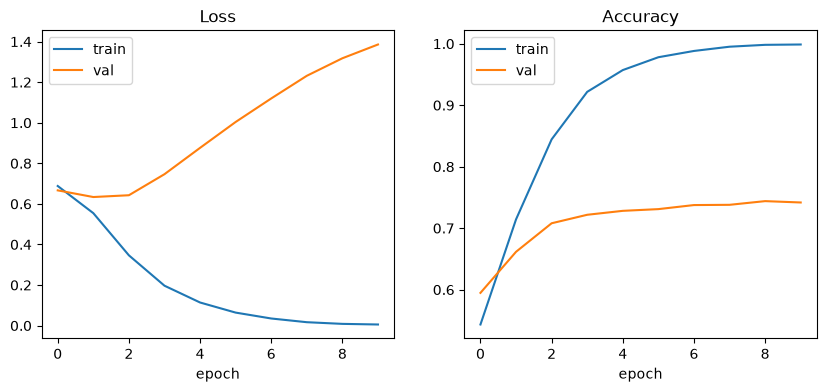

In [23]:
history = fit(net, train_loader, val_loader, epochs=10, lr=1e-3, device=device)
plot_history(history)

## Results: Embedding + Flatten (no recurrence)

| Metric | Epoch 1 | Epoch 10 |
|---|---|---|
| train acc | 0.969 | 0.997 |
| val acc | 0.696 | 0.726 |
| train loss | 0.083 | 0.011 |
| val loss | 1.278 | 2.137 |

**Observation:** strong overfitting from the very first epoch.
- Train accuracy is ~99.7%, validation accuracy only ~72%, a gap of ~27 points.
- Validation loss **increases** every epoch (1.28 -> 2.14) while train loss falls to almost zero. The model becomes more and more confident in wrong predictions.
- Validation accuracy still creeps up slightly (0.70 -> 0.73), but the loss shows the model is memorizing the training reviews, not learning general rules.

**Why it overfits:**
- The model has 262k parameters, 160k of them in `Embedding`, while we train on only 20k reviews.
- `Flatten` ties every word to a fixed position (position 5 and position 6 are treated as unrelated), so the model cannot reuse what it learned about a word at another position.
- It ignores word order and context ("not good" vs "good"), so it can only memorize word-at-position patterns.
- No regularization (no dropout, no weight decay, no early stopping).

**What this tells us:** a simple dense model on top of embeddings is a weak baseline for text. It is the reference point for the LSTM, which reads words in order and shares weights across positions.

**Ideas to improve (later experiments):**
- stop earlier (best val acc / val loss was around epoch 1-2)
- smaller `emb_dim`, dropout after `Flatten`
- LSTM instead of `Flatten`

## Step 5b. LSTM model
- [ ] fill in the shapes *before* coding:

| Layer | Output shape |
|---|---|
| input | `(batch, max_len)` |
| `Embedding` | `(batch, max_len, emb_dim)` |
| `LSTM` (last hidden state) | `(batch, hidden_dim)` |
| `Linear` | `(batch, 2)` |

- [ ] question: how to pick the "last" hidden state when padding (`0`) sits at the end of the review?
- [ ] `build_lstm(vocab_size, emb_dim, hidden_dim)`

In [46]:
class SentimentNet(nn.Module):
    """Embedding -> LSTM -> last hidden state -> Linear."""

    def __init__(self, vocab_size, emb_dim, hidden_dim, model_type="lstm"):
        """Create the layers (runs once, when the model is built)."""
        
        super().__init__()   # required first line: sets up nn.Module internals
        
        # Word index -> vector of emb_dim numbers (index 0 = <pad>, kept as zeros)
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)

        if model_type == "lstm":
            self.recurrent = nn.LSTM(emb_dim, hidden_dim, batch_first=True)
        else:
            self.recurrent = nn.RNN(emb_dim, hidden_dim, batch_first=True)
            
        # Turns the final summary into 2 scores: negative / positive
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        """Use the layers (runs on every batch, via net(xb)). x: (batch, max_len)."""
        emb = self.embedding(x)                # (batch, max_len, emb_dim)
        out, state = self.recurrent(emb)       # LSTM: state = (h_n, c_n); RNN: state = h_n

        if isinstance(state, tuple):           # LSTM -> take the hidden state only
            h_n = state[0]
        else:                                  # RNN -> state is already h_n
            h_n = state

        last = h_n[-1]                         # (batch, hidden_dim)
        return self.fc(last)                   # (batch, 2)


def build_model(vocab_size, emb_dim, hidden_dim, model_type="lstm"):
    """Create the LSTM sentiment model."""
    return SentimentNet(vocab_size, emb_dim, hidden_dim, model_type)

In [47]:
torch.manual_seed(42)
net_2 = build_model(vocab_size=10000, emb_dim=16, hidden_dim=32, model_type="lstm")
print(net_2(xb).shape)           # expected: torch.Size([64, 2])
print(count_parameters(net_2))   # expected: 166466

torch.Size([64, 2])
166466


Epoch 1/15 | train loss 0.694 acc 0.504 | val loss 0.693 acc 0.506
Epoch 2/15 | train loss 0.692 acc 0.505 | val loss 0.692 acc 0.505
Epoch 3/15 | train loss 0.690 acc 0.528 | val loss 0.691 acc 0.521
Epoch 4/15 | train loss 0.681 acc 0.565 | val loss 0.656 acc 0.631
Epoch 5/15 | train loss 0.643 acc 0.640 | val loss 0.660 acc 0.611
Epoch 6/15 | train loss 0.620 acc 0.677 | val loss 0.622 acc 0.674
Epoch 7/15 | train loss 0.586 acc 0.710 | val loss 0.612 acc 0.699
Epoch 8/15 | train loss 0.558 acc 0.736 | val loss 0.648 acc 0.667
Epoch 9/15 | train loss 0.520 acc 0.766 | val loss 0.551 acc 0.746
Epoch 10/15 | train loss 0.495 acc 0.783 | val loss 0.549 acc 0.748
Epoch 11/15 | train loss 0.469 acc 0.795 | val loss 0.530 acc 0.764
Epoch 12/15 | train loss 0.452 acc 0.811 | val loss 0.523 acc 0.775
Epoch 13/15 | train loss 0.432 acc 0.820 | val loss 0.521 acc 0.770
Epoch 14/15 | train loss 0.412 acc 0.835 | val loss 0.541 acc 0.774
Epoch 15/15 | train loss 0.397 acc 0.844 | val loss 0.502

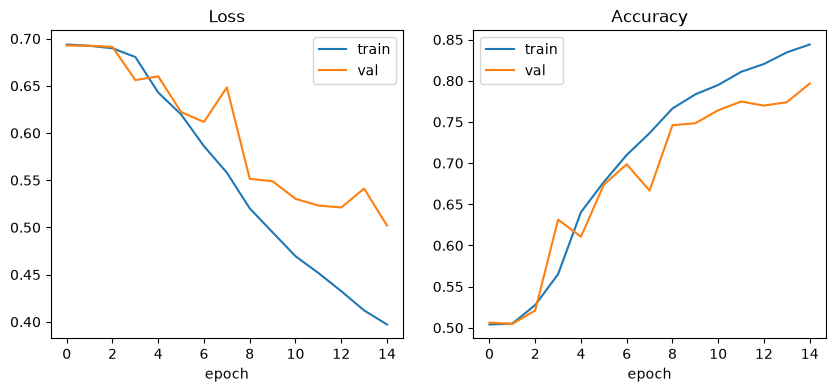

In [48]:
history_2 = fit(net_2, train_loader, val_loader, epochs=15, lr=1e-3, device=device)
plot_history(history_2)

## Results: LSTM (emb_dim=16, hidden_dim=32, max_len=200)

| Metric | Epoch 1 | Best | Epoch 10 |
|---|---|---|---|
| val acc | 0.813 | 0.828 (epoch 3) | 0.823 |
| train acc | 0.905 | | 0.944 |
| val loss | 0.495 | 0.495 (epoch 1) | 0.551 |

**Observation:** LSTM beats the Flatten network by ~10 points of validation accuracy (0.83 vs 0.73) with fewer parameters (166k vs 262k).
- Val accuracy plateaus at ~0.82 from epoch 2; val loss is lowest in epoch 1 and then slowly rises while train loss keeps falling, so there is mild overfitting (train-val gap ~12 points vs ~27 for Flatten).
- More epochs do not help; the best stopping point is around epoch 2-3.

**Why LSTM is better:** it reads words in order and shares weights across positions, so it can use context ("not good") and does not need a separate weight for every position like Flatten.

PIPLINE

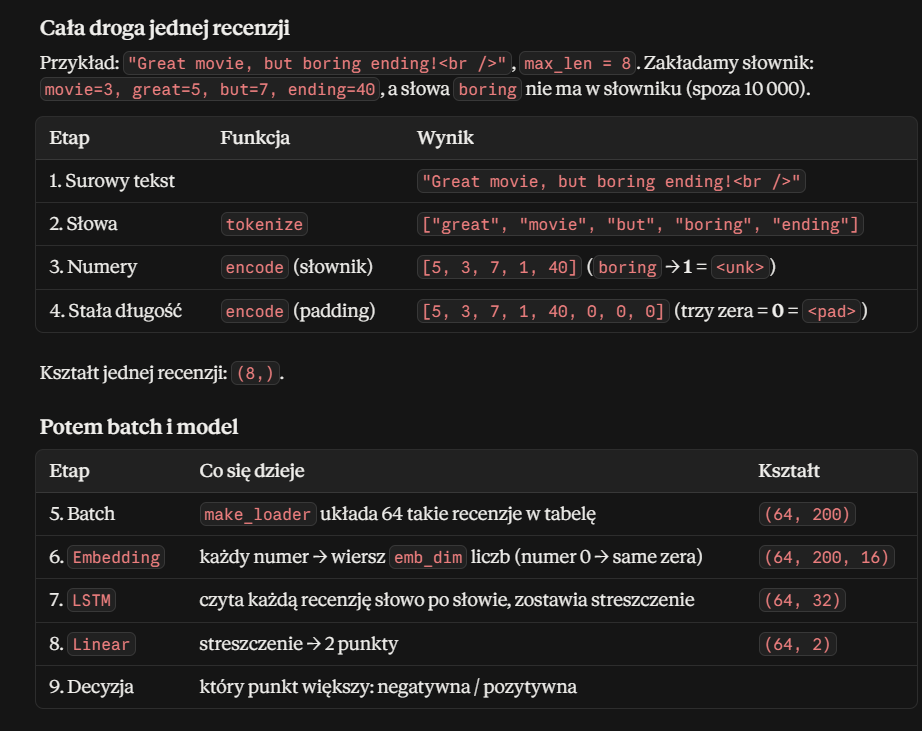

## Baseline without a neural network: TF-IDF + Logistic Regression

**Pipeline:**

```
review text -> TfidfVectorizer -> sparse vector (10,000 weights) -> LogisticRegression -> negative / positive
```

**How it works:**
1. **`TfidfVectorizer`** tokenizes the text, builds a vocabulary of the 10,000 most frequent words and turns each review into one vector of word weights.
2. **Weight of a word = TF x IDF**
   - **TF** (term frequency): how often the word appears in *this* review
   - **IDF** (inverse document frequency): how *rare* the word is across all reviews, so `the` / `movie` get small weights and `boring` / `excellent` get large ones
   - each row is normalized to length 1, so long reviews do not dominate
3. **`LogisticRegression`** learns one weight per word: positive for words like `excellent`, negative for words like `waste`.

**Rules:**
- `fit_transform` on **train only** (learns vocabulary and IDF), `transform` on validation (no learning, no leakage)
- no word order: "not good" and "good not" give the same vector
- no `Embedding`, no neural network, trains in seconds

**Why we need it:** a baseline. If a simple model matches the LSTM, the network added little.

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [31]:
def run_tfidf_baseline(train_texts, train_labels, val_texts, val_labels):
    """Train TF-IDF + Logistic Regression and return validation accuracy."""
    # 1. Text -> TF-IDF vectors (learn the vocabulary and IDF weights on TRAIN only)
    vectorizer = TfidfVectorizer(max_features=10000)
    x_train = vectorizer.fit_transform(train_texts)
    x_val = vectorizer.transform(val_texts)

    # 2. Train the classifier on the training vectors
    clf = LogisticRegression(max_iter=1000)
    clf.fit(x_train, train_labels)

    # 3. Predict on validation
    val_pred = clf.predict(x_val)       # predict for the validation vectors

    acc = accuracy_score(val_labels, val_pred)    # compare the TRUE validation labels with the predictions
    return acc

In [32]:
tfidf_acc = run_tfidf_baseline(train_texts, train_labels, val_texts, val_labels)
print(tfidf_acc)

0.8818


## Model comparison (validation set, 5,000 reviews)

| Model | Input representation | Params | Best val acc | Best epoch |
|---|---|---|---|---|
| TF-IDF + Logistic Regression | TF-IDF vector (10,000 words) | ~10,000 | 0.88 | n/a (single fit) |
| Embedding + Flatten + Dense | first 200 tokens, learned embeddings | 262,498 | 0.726 | 10 |
| Embedding + LSTM | first 200 tokens, learned embeddings | 166,466 | 0.828 | 3 |
| Embedding + RNN | first 200 tokens, learned embeddings | | | |

### How each model works

**TF-IDF + Logistic Regression**
Each review becomes one vector of 10,000 numbers. Each number is the word's weight:
TF (how often the word appears in this review) x IDF (how rare the word is across all reviews).
Common words ("the") get low weight, informative words ("awful") get high weight.
Logistic regression is basically one Linear layer: it learns one weight per word
(positive or negative sentiment) and sums them up. No word order, no training epochs.

**Embedding + Flatten + Dense**
Each token index is mapped to a learned vector (embedding). The (200, emb_dim) matrix is
flattened into one long vector and passed through Dense layers. The model sees every
position separately, so it cannot reuse what it learned about a word at another position
and it overfits quickly (huge Linear layer, 3200 -> 32).

**Embedding + RNN**
Reads the review word by word and keeps a hidden state (short-term memory), which is
overwritten at every step. Word order matters, but gradients vanish over long sequences,
so early words are quickly forgotten.

**Embedding + LSTM**
Like an RNN, but with a separate cell state (a "notebook") controlled by three gates:
forget (what to erase), input (what to write), output (what to show).
This lets it keep important information over long reviews and mitigates vanishing gradients.
The last hidden state h_n[-1] goes to the Linear(hidden_dim, 2) classifier.

### Takeaways
- Simple TF-IDF baseline beats both neural nets so far: sentiment on IMDB is largely
  driven by keywords, and we only have 20k training reviews.
- LSTM > Flatten by ~10 points: sequence models share weights across positions.
- Always build a cheap baseline first.

RNN model

In [49]:
torch.manual_seed(42)
net_rnn = build_model(vocab_size=10000, emb_dim=16, hidden_dim=32, model_type="rnn")
print(net_rnn(xb).shape)           # expected: torch.Size([64, 2])
print(count_parameters(net_rnn))   # your guess first

torch.Size([64, 2])
161666


Epoch 1/15 | train loss 0.695 acc 0.497 | val loss 0.694 acc 0.501
Epoch 2/15 | train loss 0.693 acc 0.502 | val loss 0.694 acc 0.513
Epoch 3/15 | train loss 0.692 acc 0.516 | val loss 0.694 acc 0.503
Epoch 4/15 | train loss 0.688 acc 0.529 | val loss 0.697 acc 0.507
Epoch 5/15 | train loss 0.684 acc 0.536 | val loss 0.696 acc 0.522
Epoch 6/15 | train loss 0.678 acc 0.547 | val loss 0.700 acc 0.522
Epoch 7/15 | train loss 0.668 acc 0.565 | val loss 0.706 acc 0.528
Epoch 8/15 | train loss 0.659 acc 0.577 | val loss 0.692 acc 0.568
Epoch 9/15 | train loss 0.648 acc 0.586 | val loss 0.714 acc 0.524
Epoch 10/15 | train loss 0.638 acc 0.592 | val loss 0.726 acc 0.519
Epoch 11/15 | train loss 0.624 acc 0.614 | val loss 0.737 acc 0.520
Epoch 12/15 | train loss 0.610 acc 0.628 | val loss 0.745 acc 0.525
Epoch 13/15 | train loss 0.597 acc 0.653 | val loss 0.739 acc 0.604
Epoch 14/15 | train loss 0.587 acc 0.664 | val loss 0.723 acc 0.608
Epoch 15/15 | train loss 0.560 acc 0.710 | val loss 0.739

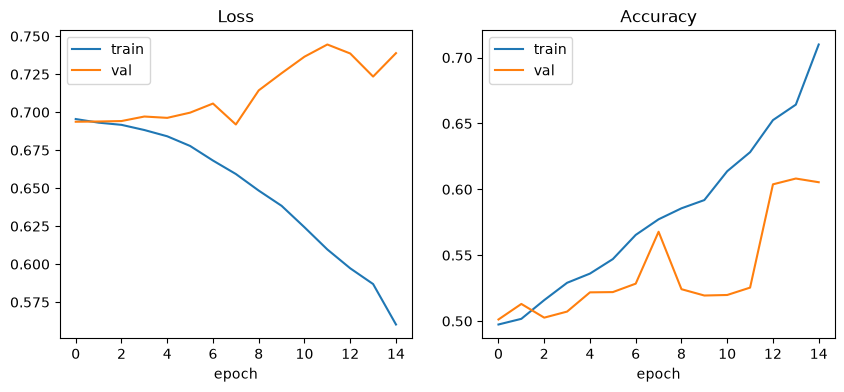

In [50]:
history_3 = fit(net_rnn, train_loader, val_loader, epochs=15, lr=1e-3, device=device)
plot_history(history_3)

## Model comparison (validation set, 5,000 reviews)

| Model | Input representation | Params | Best val acc | Best epoch |
|---|---|---|---|---|
| TF-IDF + Logistic Regression | TF-IDF vector (10,000 words) | ~10,000 | 0.88 | n/a (single fit) |
| Embedding + Flatten + Dense | first 200 tokens, learned embeddings | 262,498 | 0.726 | 10 |
| Embedding + LSTM | first 200 tokens, learned embeddings | 166,466 | 0.828 | 3 |
| Embedding + RNN | first 200 tokens, learned embeddings | 161,666 | ~0.60 | 12 |

### RNN notes
- Train acc ~0.70 vs val ~0.60: not classic overfitting, the model barely learns.
- Likely causes: vanishing gradient (plain RNN overwrites its state every step) and
  trailing padding (the final hidden state comes after many <pad> steps).
- Hypothesis to test: shorter `max_len` (100) should help the RNN.

## Step 7. Experiments
- [ ] `run_experiment` + results table

| Experiment | What it tests |
|---|---|
| `nn.RNN` vs `nn.LSTM` | does LSTM handle long reviews better? |
| `max_len` 100 vs 400 | effect of sequence length |
| `hidden_dim` 32 vs 128 | model capacity |
| (optional) `bidirectional=True` | reading in both directions |
| (optional) pretrained GloVe in `Embedding` | transfer learning for words |

In [53]:
def run_experiment(name, model_type, hidden_dim, max_len, lr, epochs):
    """Build data + model, train it and return the best validation accuracy."""
    # 1. Same random start for every experiment, so results are comparable
    torch.manual_seed(42)

    # 2. Encode the texts again with this experiment's max_len
    train_loader = make_loader(train_texts, train_labels, vocab, max_len, 64, True)
    val_loader = make_loader(val_texts, val_labels, vocab, max_len, 64, False)

    # 3. Build the model for this experiment.
    net = build_model(vocab_size=10000, emb_dim=16, hidden_dim=hidden_dim, model_type=model_type)
    
    # 4. Fit the model
    history = fit(net, train_loader, val_loader, epochs, lr, device, clip=1.0) 

    # 5. Catch best acc and epoch
    best_acc = max(history["val_acc"])
    best_epoch = history["val_acc"].index(best_acc) + 1

    # 6. Report the result
    print(f"{name}: best val acc {best_acc:.3f} at epoch {best_epoch}")
    return best_acc, best_epoch

FINAL 

In [60]:
import pandas as pd

In [67]:
results = []
for model_type in ["lstm", "rnn"]:
    for max_len in [100, 200, 400]:
        for hidden_dim in [32, 128]:
            name = f"{model_type}_len{max_len}_h{hidden_dim}"
            acc, epoch = run_experiment(name, model_type, hidden_dim, max_len, 5e-3, 8)
            results.append({
                "model": model_type,
                "max_len": max_len,
                "hidden_dim": hidden_dim,
                "best_val_acc": acc,
                "best_epoch": epoch})# TODO: which fields?

df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False)

Epoch 1/8 | train loss 0.686 acc 0.554 | val loss 0.650 acc 0.626
Epoch 2/8 | train loss 0.584 acc 0.712 | val loss 0.538 acc 0.759
Epoch 3/8 | train loss 0.446 acc 0.804 | val loss 0.440 acc 0.790
Epoch 4/8 | train loss 0.338 acc 0.860 | val loss 0.422 acc 0.808
Epoch 5/8 | train loss 0.266 acc 0.897 | val loss 0.485 acc 0.813
Epoch 6/8 | train loss 0.208 acc 0.922 | val loss 0.473 acc 0.810
Epoch 7/8 | train loss 0.161 acc 0.944 | val loss 0.538 acc 0.805
Epoch 8/8 | train loss 0.119 acc 0.962 | val loss 0.591 acc 0.811
lstm_len100_h32: best val acc 0.813 at epoch 5
Epoch 1/8 | train loss 0.684 acc 0.554 | val loss 0.646 acc 0.644
Epoch 2/8 | train loss 0.601 acc 0.687 | val loss 0.563 acc 0.735
Epoch 3/8 | train loss 0.470 acc 0.789 | val loss 0.494 acc 0.779
Epoch 4/8 | train loss 0.359 acc 0.849 | val loss 0.460 acc 0.797
Epoch 5/8 | train loss 0.283 acc 0.886 | val loss 0.443 acc 0.809
Epoch 6/8 | train loss 0.220 acc 0.916 | val loss 0.485 acc 0.809
Epoch 7/8 | train loss 0.165 

In [68]:
df

,model,max_len,hidden_dim,best_val_acc,best_epoch
4,lstm,400,32,0.8706,7
5,lstm,400,128,0.8660,6
2,lstm,200,32,0.8532,5
3,lstm,200,128,0.8524,5
0,lstm,100,32,0.8132,5
1,lstm,100,128,0.8094,6
10,rnn,400,32,0.7586,8
9,rnn,200,128,0.7480,8
11,rnn,400,128,0.7102,7
8,rnn,200,32,0.6886,7


Training best model

In [70]:
torch.manual_seed(42)    # same seed as in the grid, so we should reproduce the run
test_set = ds["test"]

test_texts = [r["text"] for r in test_set]
test_labels = [r["label"] for r in test_set]
train_loader = make_loader(train_texts, train_labels, vocab, 400, 64, True)
val_loader = make_loader(val_texts, val_labels, vocab, 400, 64, False)
test_loader = make_loader(test_texts, test_labels, vocab, 400, 64, False)

# 2. Build the winning model
net = build_model(vocab_size=10000, emb_dim=16, hidden_dim=32, model_type="lstm")

# 3. Train for exactly best_epoch epochs (fit keeps the weights of the LAST epoch)
history = fit(net, train_loader, val_loader, 7, 5e-3, device, clip=1.0)
print("val acc at epoch 7:", history["val_acc"][-1])   # expected: ~0.8706

# 4. Final test, one time only
test_loss, test_acc = evaluate(net, test_loader, nn.CrossEntropyLoss(), device)
print(f"test acc: {test_acc:.4f}")

Epoch 1/7 | train loss 0.618 acc 0.648 | val loss 0.532 acc 0.739
Epoch 2/7 | train loss 0.448 acc 0.804 | val loss 0.438 acc 0.822
Epoch 3/7 | train loss 0.325 acc 0.866 | val loss 0.379 acc 0.828
Epoch 4/7 | train loss 0.252 acc 0.903 | val loss 0.369 acc 0.829
Epoch 5/7 | train loss 0.202 acc 0.925 | val loss 0.350 acc 0.864
Epoch 6/7 | train loss 0.159 acc 0.943 | val loss 0.352 acc 0.864
Epoch 7/7 | train loss 0.127 acc 0.956 | val loss 0.417 acc 0.871
val acc at epoch 7: 0.8706
test acc: 0.8618


result of the best model - val acc - 87 and test acc 86